# 🎬 Netflix Content Analysis & Boosting Project
## Can we predict whether a Netflix title is for mature audiences?

| | |
|---|---|
| **Student Name** | Garvit Singh |
| **Course / Batch** | AIML Batch (Unlox) |
| **Dataset Name** | Netflix Movies and TV Shows (`netflix_titles_nov_2019.csv`) |
| **Kaggle Link** | *(paste your Kaggle dataset link here)* |
| **Approach** | Classification using **Boosting** (AdaBoost and Gradient Boosting) |

**Dataset description:** a list of 5,837 movies and TV shows available on Netflix in November 2019, with details such as type, title, director, cast, country, date added, release year, rating, duration, genres and a short description. It is real data, collected from Netflix.

*In Google Colab: click Runtime → Run all, and upload `netflix_titles_nov_2019.csv` when asked.*

---
# 1. Define the Problem

**Question:** Using only simple facts about a title (its type, genres, country, release year, length and when it was added), can a machine learning model predict whether it is **mature content** (rated TV-MA, R or NC-17)?

**Why it matters:** Netflix has thousands of titles. Predicting the maturity level can help to
- warn parents about titles that have no rating yet,
- build better parental-control and "kids profile" filters,
- understand what kind of content Netflix offers.

**Task type:** Binary **classification** (1 = mature, 0 = not mature).
**Method:** **Boosting**: many small decision trees are built one after another, and each new tree focuses on the mistakes of the previous trees.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report

sns.set_style("whitegrid")

In [2]:
# Upload the file (only works in Google Colab, it is skipped on a normal computer)
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not in Colab, using the file in this folder.")

Not in Colab, using the file in this folder.


In [3]:
df = pd.read_csv("netflix_titles_nov_2019.csv")
df.head()

,show_id,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,type
0,81193313,Chocolate,NaN,"Ha Ji-won, Yoon Kye-sang, Jang Seung-jo, Kang ...",South Korea,"November 30, 2019",2019,TV-14,1 Season,"International TV Shows, Korean TV Shows, Roman...",Brought together by meaningful meals in the pa...,TV Show
1,81197050,Guatemala: Heart of the Mayan World,"Luis Ara, Ignacio Jaunsolo",Christian Morales,NaN,"November 30, 2019",2019,TV-G,67 min,"Documentaries, International Movies","From Sierra de las Minas to Esquipulas, explor...",Movie
2,81213894,The Zoya Factor,Abhishek Sharma,"Sonam Kapoor, Dulquer Salmaan, Sanjay Kapoor, ...",India,"November 30, 2019",2019,TV-14,135 min,"Comedies, Dramas, International Movies",A goofy copywriter unwittingly convinces the I...,Movie
3,81082007,Atlantics,Mati Diop,"Mama Sane, Amadou Mbow, Ibrahima Traore, Nicol...","France, Senegal, Belgium","November 29, 2019",2019,TV-14,106 min,"Dramas, Independent Movies, International Movies","Arranged to marry a rich man, young Ada is cru...",Movie
4,80213643,Chip and Potato,NaN,"Abigail Oliver, Andrea Libman, Briana Buckmast...","Canada, United Kingdom",NaN,2019,TV-Y,2 Seasons,Kids' TV,"Lovable pug Chip starts kindergarten, makes ne...",TV Show


---
# 2. Understand the Data

In [4]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (5837, 12)
<class 'pandas.DataFrame'>
RangeIndex: 5837 entries, 0 to 5836
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       5837 non-null   int64
 1   title         5837 non-null   str  
 2   director      3936 non-null   str  
 3   cast          5281 non-null   str  
 4   country       5410 non-null   str  
 5   date_added    5195 non-null   str  
 6   release_year  5837 non-null   int64
 7   rating        5827 non-null   str  
 8   duration      5837 non-null   str  
 9   listed_in     5837 non-null   str  
 10  description   5837 non-null   str  
 11  type          5837 non-null   str  
dtypes: int64(2), str(10)
memory usage: 547.3 KB


| Column | Meaning |
|---|---|
| `show_id` | Unique number of the title |
| `title` | Name of the movie / show |
| `director`, `cast` | People involved (text) |
| `country` | Country (or countries) that produced it |
| `date_added` | Date it was added to Netflix |
| `release_year` | Year it was originally released |
| `rating` | Age rating (TV-MA, PG, R ...) → **we will use this to build our target** |
| `duration` | Minutes for movies, number of seasons for TV shows |
| `listed_in` | Genres (several, separated by commas) |
| `description` | Short story summary |
| `type` | Movie or TV Show |

**Target variable:** `is_mature`, which we create from `rating`. **Important features:** type, genres, country, release year, duration, and when the title was added.

In [5]:
# What ratings exist and how many titles have each?
df["rating"].value_counts()

rating
TV-MA       1937
TV-14       1593
TV-PG        678
R            439
PG-13        227
NR           218
PG           160
TV-Y7        156
TV-G         147
TV-Y         139
TV-Y7-FV      92
G             32
UR             7
NC-17          2
Name: count, dtype: int64

---
# 3. Check Data Quality

In [6]:
# Missing values
missing = pd.DataFrame({"Missing": df.isnull().sum(),
                        "Missing %": (df.isnull().sum() / len(df) * 100).round(1)})
missing[missing["Missing"] > 0]

,Missing,Missing %
director,1901,32.6
cast,556,9.5
country,427,7.3
date_added,642,11.0
rating,10,0.2


In [7]:
# Duplicates
print("Completely duplicated rows      :", df.duplicated().sum())
print("Duplicated show_id              :", df["show_id"].duplicated().sum())
print("Duplicated (title+type+year)    :", df.duplicated(subset=["title", "type", "release_year"]).sum())
print("Titles that appear more than once:", df["title"].duplicated().sum())

Completely duplicated rows      : 0
Duplicated show_id              : 0
Duplicated (title+type+year)    : 3
Titles that appear more than once: 57


In [8]:
# Data types and unusual values
print("Data types:")
print(df.dtypes)
print()
print("Oldest release year:", df["release_year"].min(), "| Newest:", df["release_year"].max())
print()
print("Example duration values:", df["duration"].unique()[:10])

Data types:
show_id         int64
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
type              str
dtype: object

Oldest release year: 1925 | Newest: 2020

Example duration values: <StringArray>
[ '1 Season',    '67 min',   '135 min',   '106 min', '2 Seasons',   '107 min',
    '81 min',   '118 min',   '110 min',   '104 min']
Length: 10, dtype: str


**Data-quality findings**

| Issue | Finding | Decision |
|---|---|---|
| Missing `director` | 1,901 (32.6%) | Drop the column. Too much is missing and almost every director is different. |
| Missing `cast` | 556 (9.5%) | Drop the column. Almost every cast list is different, so it is not useful for a simple model. |
| Missing `country` | 427 (7.3%) | Fill with "Unknown". |
| Missing `date_added` | 642 (11.0%) | Fill the year and month with the median value. |
| Missing `rating` | 10 (0.2%) | Drop these rows, because we need the rating to make the target. |
| Duplicates | No fully duplicated rows and no repeated `show_id`. The few repeated titles have different years or types (remakes), so they are different titles. | Keep them. |
| Wrong data types | `date_added` is text; `duration` is text like "90 min" / "2 Seasons" | Convert to a date and to numbers. |
| Unusual values | Release years go back to 1925 (old films) | Keep them, they are real old titles. |

---
# 4. Prepare the Data (cleaning, step by step)

In [9]:
# Step 1: drop rows with no rating (we cannot build the target for them)
before = len(df)
df = df.dropna(subset=["rating"]).copy()
print("Rows removed:", before - len(df), "| Rows left:", len(df))

Rows removed: 10 | Rows left: 5827


In [10]:
# Step 2: create the target. Mature = TV-MA, R or NC-17
mature_ratings = ["TV-MA", "R", "NC-17"]
df["is_mature"] = df["rating"].isin(mature_ratings).astype(int)

print(df["is_mature"].value_counts())
print()
print((df["is_mature"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

is_mature
0    3449
1    2378
Name: count, dtype: int64

is_mature
0    59.2 %
1    40.8 %
Name: proportion, dtype: str


In [11]:
# Step 3: turn duration text into a number ("90 min" -> 90, "2 Seasons" -> 2)
df["duration_num"] = df["duration"].str.split(" ").str[0].astype(int)
df[["type", "duration", "duration_num"]].head()

,type,duration,duration_num
0,TV Show,1 Season,1
1,Movie,67 min,67
2,Movie,135 min,135
3,Movie,106 min,106
4,TV Show,2 Seasons,2


In [12]:
# Step 4: date_added -> year and month (fill missing values with the median)
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

df["year_added"] = df["year_added"].fillna(df["year_added"].median())
df["month_added"] = df["month_added"].fillna(df["month_added"].median())
print("Missing in year_added :", df["year_added"].isnull().sum())
print("Missing in month_added:", df["month_added"].isnull().sum())

Missing in year_added : 0
Missing in month_added: 0


In [13]:
# Step 5: country -> keep the first country, fill missing with "Unknown"
df["country"] = df["country"].fillna("Unknown")
df["main_country"] = df["country"].str.split(",").str[0].str.strip()

# Keep the 8 most common countries, call the rest "Other"
top_countries = df["main_country"].value_counts().head(8).index
df["country_group"] = df["main_country"].where(df["main_country"].isin(top_countries), "Other")
df["country_group"].value_counts()

country_group
United States     2138
Other             1427
India              726
United Kingdom     456
Unknown            423
Canada             201
Japan              175
South Korea        141
France             140
Name: count, dtype: int64

In [14]:
# Step 6: genres -> count of genres + a 0/1 column for the 12 most common genres
df["genre_list"] = df["listed_in"].str.split(", ")
df["num_genres"] = df["genre_list"].str.len()

all_genres = df["genre_list"].explode()
top_genres = all_genres.value_counts().head(12).index.tolist()
print("Top 12 genres:", top_genres)

for g in top_genres:
    df["genre_" + g] = df["genre_list"].apply(lambda lst: 1 if g in lst else 0)

Top 12 genres: ['International Movies', 'Dramas', 'Comedies', 'International TV Shows', 'Documentaries', 'TV Dramas', 'Action & Adventure', 'Independent Movies', 'TV Comedies', 'Crime TV Shows', 'Thrillers', 'Children & Family Movies']


In [15]:
# Step 7: type -> 0/1 (1 = Movie)
df["is_movie"] = (df["type"] == "Movie").astype(int)
print(df["is_movie"].value_counts())

is_movie
1    3931
0    1896
Name: count, dtype: int64


### 🧾 Data-cleaning summary
1. Dropped 10 rows without a rating (5,837 → 5,827 titles).
2. Created the target `is_mature` (TV-MA, R, NC-17 = 1; everything else = 0).
3. Converted `duration` to a number, and `date_added` to year and month (missing dates filled with the median).
4. Filled missing `country` with "Unknown", kept the first country, and grouped small countries into "Other".
5. Turned the genre list into `num_genres` and 12 yes/no genre columns.
6. Left out `director`, `cast`, `title`, `description` and `show_id` (identifier/text columns that a simple model cannot use well).

---
# 5. Explore and Visualize

### Visualization 1: Movies vs. TV Shows

type
Movie      3931
TV Show    1896
Name: count, dtype: int64


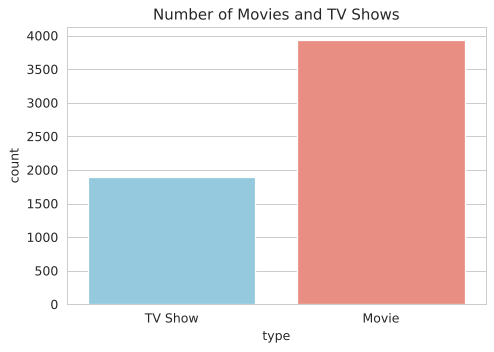

In [16]:
plt.figure(figsize=(6, 4))
sns.countplot(x="type", data=df, hue="type", palette=["skyblue", "salmon"], legend=False)
plt.title("Number of Movies and TV Shows")
plt.show()

print(df["type"].value_counts())

**Observation:** Movies are about two times more common than TV shows (roughly 68% vs 32%), so Netflix's 2019 catalogue is mostly movies.

### Visualization 2: How many titles were added each year?

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       7
2013.0       9
2014.0      19
2015.0      72
2016.0     409
2017.0    1181
2018.0    2269
2019.0    1843
dtype: int64


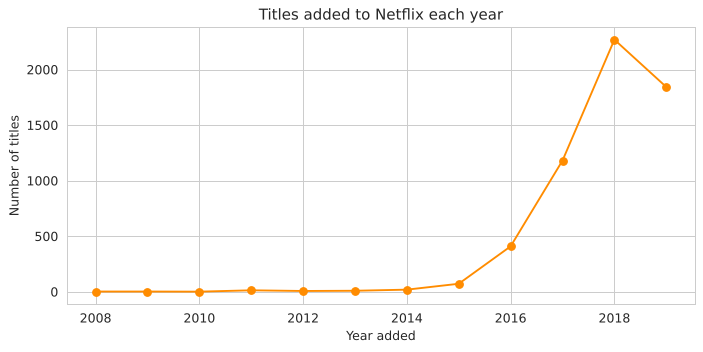

In [17]:
added_per_year = df.groupby("year_added").size()
added_per_year = added_per_year[added_per_year.index >= 2008]

plt.figure(figsize=(9, 4))
plt.plot(added_per_year.index, added_per_year.values, marker="o", color="darkorange")
plt.title("Titles added to Netflix each year")
plt.xlabel("Year added")
plt.ylabel("Number of titles")
plt.show()

print(added_per_year)

**Observation:** Netflix added very few titles before 2015, then growth exploded. (The last year looks different because this file ends in November 2019 and some dates are missing and were filled with the median.)

### Visualization 3: Top 10 countries

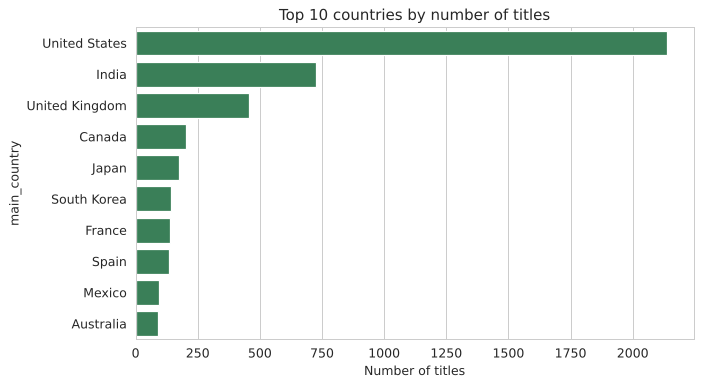

In [18]:
top10 = df[df["main_country"] != "Unknown"]["main_country"].value_counts().head(10)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=top10.values, y=top10.index, color="seagreen")
plt.title("Top 10 countries by number of titles")
plt.xlabel("Number of titles")
plt.show()

**Observation:** The United States is far ahead, then India and the United Kingdom. The catalogue is strongly US-centred, but India is a big source of content too.

### Visualization 4: Top 10 genres

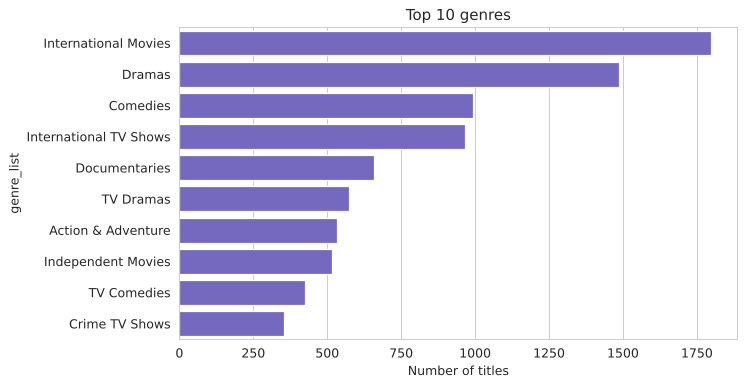

In [19]:
top10_genres = all_genres.value_counts().head(10)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=top10_genres.values, y=top10_genres.index, color="slateblue")
plt.title("Top 10 genres")
plt.xlabel("Number of titles")
plt.show()

**Observation:** International Movies and Dramas are the most common genres, followed by Comedies and International TV Shows. Netflix has a lot of drama and non-US content.

### Visualization 5: Age ratings

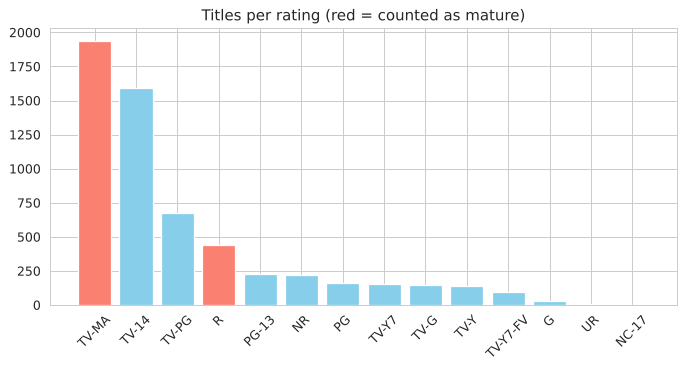

In [20]:
rating_counts = df["rating"].value_counts()

plt.figure(figsize=(9, 4))
colors = ["salmon" if r in mature_ratings else "skyblue" for r in rating_counts.index]
plt.bar(rating_counts.index, rating_counts.values, color=colors)
plt.title("Titles per rating (red = counted as mature)")
plt.xticks(rotation=45)
plt.show()

**Observation:** TV-MA is the single most common rating, followed by TV-14. About **41% of titles are mature** (red bars), so our target is reasonably balanced and fine for classification.

### Visualization 6: Which kinds of titles are more often mature?

type
Movie      43.9
TV Show    34.3
Name: is_mature, dtype: float64

Children & Family Movies     0.0
Documentaries               32.1
Comedies                    34.5
TV Comedies                 37.3
International Movies        40.6
International TV Shows      40.8
TV Dramas                   45.8
Dramas                      46.3
Action & Adventure          50.4
Crime TV Shows              62.3
Independent Movies          66.3
Thrillers                   67.7
dtype: float64


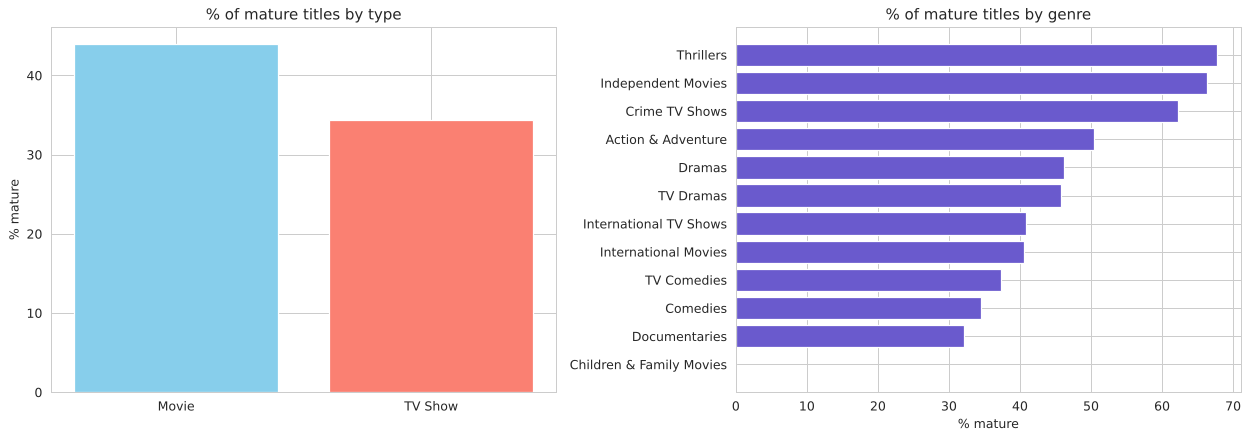

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By type
mature_by_type = df.groupby("type")["is_mature"].mean() * 100
axes[0].bar(mature_by_type.index, mature_by_type.values, color=["skyblue", "salmon"])
axes[0].set_title("% of mature titles by type")
axes[0].set_ylabel("% mature")

# By genre
mature_by_genre = pd.Series({g: df.loc[df["genre_" + g] == 1, "is_mature"].mean() * 100 for g in top_genres})
mature_by_genre = mature_by_genre.sort_values()
axes[1].barh(mature_by_genre.index, mature_by_genre.values, color="slateblue")
axes[1].set_title("% of mature titles by genre")
axes[1].set_xlabel("% mature")

plt.tight_layout()
plt.show()

print(mature_by_type.round(1))
print()
print(mature_by_genre.round(1))

**Observation:** Genre is a strong clue for maturity (see the numbers printed above the chart). Family and kids content is rarely mature, while thrillers, crime and action are often mature. This tells us the genre columns should be useful for the model.

### Visualization 7: Release year and maturity

is_mature
0    2016.0
1    2017.0
Name: release_year, dtype: float64


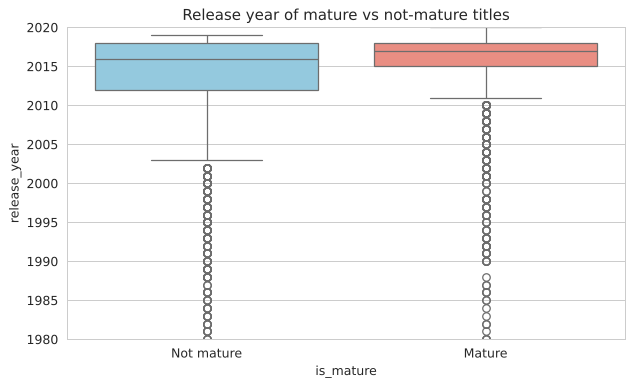

In [22]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(x="is_mature", y="release_year", data=df, hue="is_mature", palette=["skyblue", "salmon"], legend=False)
plt.ylim(1980, 2020)
plt.xticks([0, 1], ["Not mature", "Mature"])
plt.title("Release year of mature vs not-mature titles")
plt.show()

print(df.groupby("is_mature")["release_year"].median())

**Observation:** see the median release years printed above: mature and not-mature titles have a similar release-year range, so release year alone is not a strong clue.

---
# 6. Choose the Approach

**Task:** classification (is the title mature: yes or no).

**Why Boosting?** Boosting builds many *weak* models (small decision trees) one after another. Every new tree pays extra attention to the titles the earlier trees got wrong. The final answer is a weighted vote of all trees. It usually beats one single tree, and it works well on tables with a mix of numbers and yes/no columns like ours.

We will compare three models:
1. **Single Decision Tree** (small, depth 3): our simple baseline
2. **AdaBoost**: boosting that gives more weight to wrongly predicted titles
3. **Gradient Boosting**: boosting where each new tree corrects the errors of the previous trees

In [23]:
# One-hot encode country_group (text -> 0/1 columns)
df_model = pd.get_dummies(df, columns=["country_group"], drop_first=True, dtype=int)

# Choose the features (X) and the target (y)
feature_cols = (["is_movie", "release_year", "duration_num", "year_added", "month_added", "num_genres"]
                + ["genre_" + g for g in top_genres]
                + [c for c in df_model.columns if c.startswith("country_group_")])

X = df_model[feature_cols]
y = df_model["is_mature"]

print("Number of features:", X.shape[1])
print("Rows:", X.shape[0])

Number of features: 26
Rows: 5827


In [24]:
# 80% training, 20% testing (random_state=42 -> same split every time)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 4661
Testing rows : 1166


---
# 7. Evaluate the Result
### Train the three models

In [25]:
models = {
    "Decision Tree (baseline)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                                    max_depth=3, random_state=42),
}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)                       # train
    pred = m.predict(X_test)                      # predict
    prob = m.predict_proba(X_test)[:, 1]          # probability of "mature"
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "Recall": recall_score(y_test, pred),
                    "F1-Score": f1_score(y_test, pred),
                    "ROC-AUC": roc_auc_score(y_test, prob)})

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (baseline),0.620,0.573,0.432,0.493,0.653
1,AdaBoost,0.689,0.669,0.536,0.595,0.734
2,Gradient Boosting,0.711,0.694,0.578,0.631,0.781


In [26]:
# Cross-validation: 5 different train/test splits for a more reliable score.
# shuffle=True is important here, because the file is sorted by date added.
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=kfold, scoring="accuracy")
    print(f"{name:26s} average accuracy = {scores.mean():.3f}  (+/- {scores.std():.3f})")

Decision Tree (baseline)   average accuracy = 0.642  (+/- 0.015)
AdaBoost                   average accuracy = 0.694  (+/- 0.010)
Gradient Boosting          average accuracy = 0.718  (+/- 0.004)


**How to read the metrics (in simple words)**
- **Accuracy:** out of 100 titles, how many are classified correctly.
- **Precision:** when the model says "mature", how often it is right.
- **Recall:** out of all really mature titles, how many the model finds.
- **F1-Score:** one number that balances precision and recall.
- **ROC-AUC:** how well the model separates mature from non-mature titles (0.5 = guessing, 1.0 = perfect).

### Detailed look at the best model: Gradient Boosting

[[541 127]
 [210 288]]


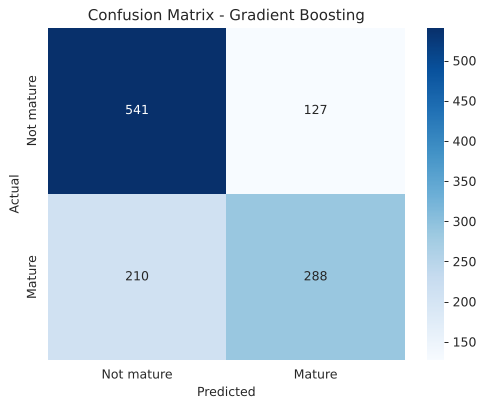

In [27]:
best_model = models["Gradient Boosting"]
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not mature", "Mature"], yticklabels=["Not mature", "Mature"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Gradient Boosting")
plt.show()

In [28]:
print(classification_report(y_test, y_pred, target_names=["Not mature", "Mature"]))

              precision    recall  f1-score   support

  Not mature       0.72      0.81      0.76       668
      Mature       0.69      0.58      0.63       498

    accuracy                           0.71      1166
   macro avg       0.71      0.69      0.70      1166
weighted avg       0.71      0.71      0.71      1166


Accuracy after 10 trees : 0.654
Accuracy after 100 trees: 0.711
Final training accuracy : 0.749


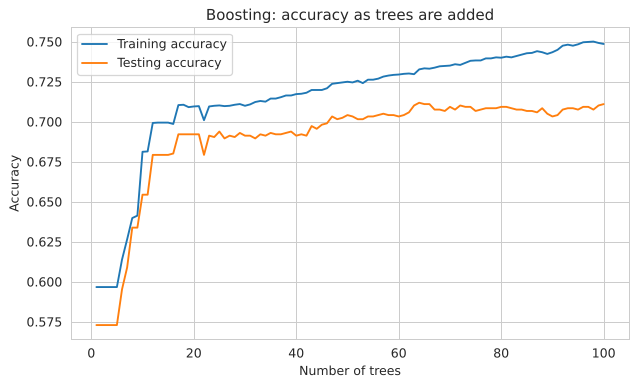

In [29]:
# How does boosting improve as more trees are added?
test_accuracy = [accuracy_score(y_test, p) for p in best_model.staged_predict(X_test)]
train_accuracy = [accuracy_score(y_train, p) for p in best_model.staged_predict(X_train)]

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 101), train_accuracy, label="Training accuracy")
plt.plot(range(1, 101), test_accuracy, label="Testing accuracy")
plt.xlabel("Number of trees")
plt.ylabel("Accuracy")
plt.title("Boosting: accuracy as trees are added")
plt.legend()
plt.show()

print("Accuracy after 10 trees :", round(test_accuracy[9], 3))
print("Accuracy after 100 trees:", round(test_accuracy[99], 3))
print("Final training accuracy :", round(train_accuracy[99], 3))

### Which features matter most?

,Feature,Importance
2,duration_num,0.236
17,genre_Children & Family Movies,0.156
1,release_year,0.130
19,country_group_India,0.080
15,genre_Crime TV Shows,0.056
13,genre_Independent Movies,0.053
4,month_added,0.048
10,genre_Documentaries,0.043
16,genre_Thrillers,0.039
3,year_added,0.027


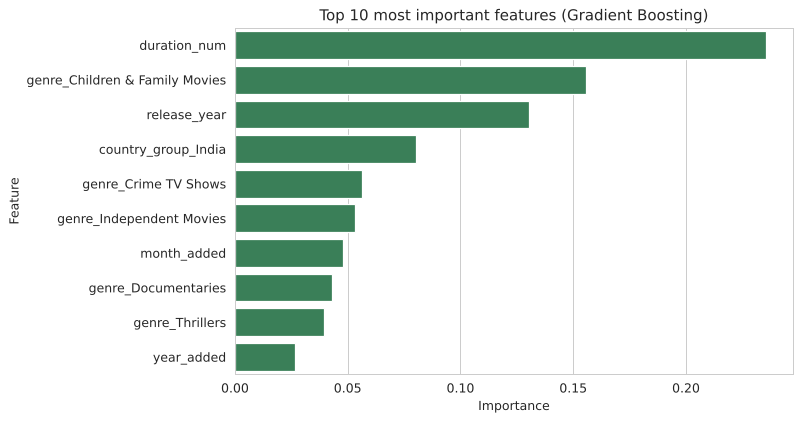

In [30]:
importance = pd.DataFrame({"Feature": X.columns, "Importance": best_model.feature_importances_})
importance = importance.sort_values("Importance", ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x="Importance", y="Feature", data=importance, color="seagreen")
plt.title("Top 10 most important features (Gradient Boosting)")
plt.show()

importance.round(3)

---
# 8. Conclude

### Final conclusion (in my own words)

I wanted to see if a model can guess whether a Netflix title is mature (TV-MA, R or NC-17) from simple facts such as its genres, country, length and release year. I cleaned the 5,837 titles (dropped 10 rows with no rating, filled missing countries and dates, and turned genres and countries into yes/no columns) and then compared a single decision tree with two boosting models.

**Results (test set of 1,166 titles):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Decision Tree (baseline) | 0.620 | 0.573 | 0.432 | 0.493 | 0.653 |
| AdaBoost | 0.689 | 0.669 | 0.536 | 0.595 | 0.734 |
| **Gradient Boosting** | **0.711** | **0.694** | **0.578** | **0.631** | **0.781** |

Gradient Boosting was the best model. It beat the single tree by about 9 percentage points in accuracy, which shows that boosting many small trees really helps. In 5-fold cross-validation it scored about 71.8% (the single tree scored 64.2%), so the result is stable. In plain words: out of 100 titles the model labels about 71 correctly. When it says "mature" it is right about 69% of the time, but it only finds about 58% of the truly mature titles (it missed 210 and wrongly flagged 127).

**Key findings:**
- Netflix's catalogue is mostly movies (about 68%), mostly US and Indian content, and about 41% of titles are mature.
- Genre is a strong clue: Thrillers, Independent Movies and Crime TV Shows are very often mature, while Children & Family Movies are never mature.
- The most important features for the model were the duration (23.6%), the Children & Family genre (15.6%), the release year (13.0%) and whether the title is from India (8.0%).

**Limitations:**
- The accuracy of about 71% is only moderate. The model does not see the story, the cast or the real content of the title, which are the things that really decide the rating.
- The model misses many mature titles (recall 58%), so it should not be used alone for parental controls.
- I used the 12 most common genres and 8 most common countries only, and missing dates were filled with the median.
- The data is from November 2019 only.

**Future improvements:** use the `description` text (for example with TF-IDF), add the cast and director, try XGBoost or LightGBM with tuning, and handle the class imbalance to improve recall.